# CP2 - Machine Learning & Modelling
## Otimização KNN Regressor - Insurance

**Turma:** 1TIAPR-2026  
**Aluno:** Gonzalo Duran RM574218

Neste trabalho vamos usar o mesmo dataset da aula e tentar melhorar as previsões dos custos médicos. Primeiro faço o modelo base, depois testo uma nova variável e diferentes parâmetros.

## 1. Bibliotecas e dataset
Vou usar as mesmas bibliotecas que vimos nos notebooks das aulas.

In [1]:
# pandas para trabalhar com as tabelas / dataframe
import pandas as pd
# numpy para algumas operações numéricas
import numpy as np
# matplotlib para visualizar os resultados
import matplotlib.pyplot as plt
# separa os dados de treino e teste, e faz a busca de parâmetros
from sklearn.model_selection import train_test_split, GridSearchCV
# aplica tratamentos diferentes para cada tipo de coluna
from sklearn.compose import ColumnTransformer
# transforma texto em números e ajusta as escalas
from sklearn.preprocessing import OneHotEncoder, StandardScaler
# junta as etapas de preparação e o modelo
from sklearn.pipeline import Pipeline
# modelo KNN para prever valores numéricos
from sklearn.neighbors import KNeighborsRegressor
# métricas
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# link do mesmo arquivo Insurance utilizado na aula
url = "https://raw.githubusercontent.com/stedy/Machine-Learning-with-R-datasets/master/insurance.csv"
# leio o csv diretamente no Colab
df = pd.read_csv(url)
# mostro as primeiras linhas para conhecer os dados
df.head()

,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061
4,32,male,28.880,0,no,northwest,3866.85520


## 2. Conhecendo e verificando os dados
Antes de treinar, quero ver as colunas, os valores faltantes e possíveis linhas repetidas. Também olho a distribuição de `charges`.

Formato: (1338, 7)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1338 entries, 0 to 1337
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype  
---  ------    --------------  -----  
 0   age       1338 non-null   int64  
 1   sex       1338 non-null   object 
 2   bmi       1338 non-null   float64
 3   children  1338 non-null   int64  
 4   smoker    1338 non-null   object 
 5   region    1338 non-null   object 
 6   charges   1338 non-null   float64
dtypes: float64(2), int64(2), object(3)
memory usage: 73.3+ KB
               age          bmi     children       charges
count  1338.000000  1338.000000  1338.000000   1338.000000
mean     39.207025    30.663397     1.094918  13270.422265
std      14.049960     6.098187     1.205493  12110.011237
min      18.000000    15.960000     0.000000   1121.873900
25%      27.000000    26.296250     0.000000   4740.287150
50%      39.000000    30.400000     1.000000   9382.033000
75%      51.000000    34.693750     2.000000  16

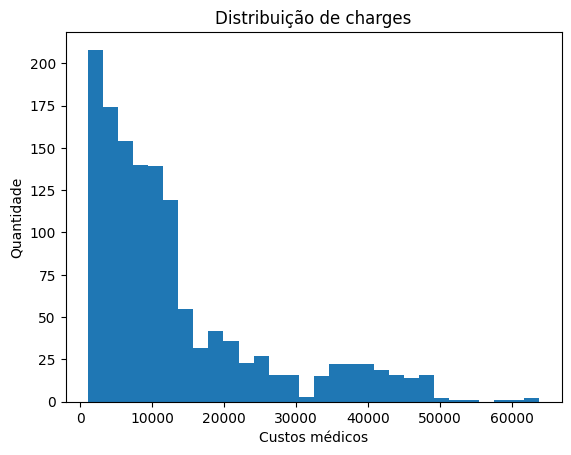

In [2]:
# quantidade de linhas e colunas
print("Formato:", df.shape)
# tipos das colunas e valores preenchidos
df.info()
# resumo das variáveis numéricas
print(df.describe())
# conto valores vazios em cada coluna
print("Valores faltantes:")
print(df.isnull().sum())
# verifico se existem registros iguais
print("Linhas duplicadas:", df.duplicated().sum())
# vejo as categorias para entender o One Hot Encoder
print("Categorias:")
for coluna in ["sex", "smoker", "region"]:
    print(coluna, df[coluna].unique())
# histograma simples da variável que queremos prever
plt.hist(df["charges"], bins=30)
plt.title("Distribuição de charges")
plt.xlabel("Custos médicos")
plt.ylabel("Quantidade")
plt.show()

**Decisão:** vou manter as linhas do dataset original para comparar nas mesmas condições da aula. Se aparecerem dados faltantes, o código vai avisar antes de treinar. Não removo valores altos de `charges` automaticamente, porque podem ser custos médicos reais.

## 3. Separação treino e teste
Faço a divisão antes de ajustar o scaler. Assim o teste não participa do aprendizado do pré-processamento.

In [3]:
# X são as informações usadas para prever
X = df.drop(columns="charges")
# y é o valor que queremos prever
y = df["charges"]
# separo 80% para treino e 20% para teste, igual na aula
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
# confiro a quantidade de registros de cada grupo
print("Treino:", X_train.shape)
print("Teste:", X_test.shape)
# verifico valores faltantes antes de treinar
print("Total de valores faltantes:", df.isnull().sum().sum())

Treino: (1070, 6)
Teste: (268, 6)
Total de valores faltantes: 0


## 4. Modelo original da aula (baseline)
Vou repetir o KNN com 5 vizinhos, pesos uniformes, StandardScaler e OneHotEncoder. Essa será nossa referência.

In [5]:
# identifico as colunas numéricas
num_cols = X.select_dtypes(include=["int64", "float64"]).columns.tolist()
# identifico as colunas de texto
cat_cols = X.select_dtypes(include=["object"]).columns.tolist()
# StandardScaler nas numéricas e OneHotEncoder nas categóricas
preprocess = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])
# monto o mesmo pipeline básico da aula
baseline = Pipeline(steps=[
    ("preprocessamento", preprocess),
    ("modelo", KNeighborsRegressor(n_neighbors=5, weights="uniform", metric="euclidean"))
])
# fit aprende usando somente os dados de treino
baseline.fit(X_train, y_train)
# predict faz previsões para os dados separados para teste
pred_baseline = baseline.predict(X_test)

## 5. Feature engineering
Vou criar `bmi_smoker`, que multiplica o BMI por 1 para fumantes e por 0 para não fumantes. A ideia é testar se a combinação dessas duas informações ajuda a encontrar vizinhos mais parecidos. É uma hipótese, não uma melhoria garantida.

Faço essa transformação separadamente no treino e no teste, sem utilizar `charges`.

In [6]:
# copio os dados para não alterar o X original
X_train_novo = X_train.copy()
X_test_novo = X_test.copy()
# crio uma variável que combina BMI com o fato de ser fumante
# se smoker for yes, usa o BMI; se for no, fica zero
X_train_novo["bmi_smoker"] = X_train_novo["bmi"] * (X_train_novo["smoker"] == "yes").astype(int)
# aplico a mesma regra nos dados de teste
X_test_novo["bmi_smoker"] = X_test_novo["bmi"] * (X_test_novo["smoker"] == "yes").astype(int)
# vejo como ficou a nova coluna
X_train_novo[["bmi", "smoker", "bmi_smoker"]].head()

,bmi,smoker,bmi_smoker
560,19.95,no,0.0
1285,24.32,no,0.0
1142,24.86,no,0.0
969,34.32,no,0.0
486,21.47,no,0.0


## 6. Scaling, encoding e busca do melhor KNN
Uso `GridSearchCV` como na segunda parte da aula, testando valores de K, tipos de peso e distâncias. A validação cruzada acontece somente no conjunto de treino.

In [7]:
# identifico as colunas numéricas, agora incluindo bmi_smoker
num_cols_novo = X_train_novo.select_dtypes(include=["int64", "float64"]).columns.tolist()
# identifico as colunas categóricas
cat_cols_novo = X_train_novo.select_dtypes(include=["object"]).columns.tolist()
# preparo os dados: StandardScaler e OneHotEncoder, como na aula
preprocess_novo = ColumnTransformer(transformers=[
    ("num", StandardScaler(), num_cols_novo),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols_novo)
])
# pipeline para fazer o tratamento e depois o KNN
pipeline_grid = Pipeline(steps=[
    ("preprocessamento", preprocess_novo),
    ("modelo", KNeighborsRegressor())
])
# combinações de parâmetros que vimos na aula
param_grid = {
    "modelo__n_neighbors": list(range(1, 21)),
    "modelo__weights": ["uniform", "distance"],
    "modelo__metric": ["euclidean", "manhattan"]
}
# grid search testa as combinações com cross validation de 5 partes
# escolho RMSE como referência: menor erro é melhor
grid = GridSearchCV(
    estimator=pipeline_grid,
    param_grid=param_grid,
    cv=5,
    scoring="neg_root_mean_squared_error",
    n_jobs=-1
)
# treino e validação somente nos dados de treino
grid.fit(X_train_novo, y_train)
# vejo quais parâmetros tiveram o melhor resultado na validação
print("Melhores parâmetros:", grid.best_params_)
# o sinal negativo é uma convenção do sklearn, por isso inverto
print("RMSE médio na validação:", -grid.best_score_)
# pego o melhor modelo encontrado
melhor_modelo = grid.best_estimator_
# finalmente faço a previsão no teste, que ficou separado
pred_melhor = melhor_modelo.predict(X_test_novo)

Melhores parâmetros: {'modelo__metric': 'euclidean', 'modelo__n_neighbors': 14, 'modelo__weights': 'distance'}
RMSE médio na validação: 5088.918167983299


## 7. Avaliação com as quatro métricas
MAE, MSE e RMSE menores indicam menos erro. Para R², maior normalmente é melhor. Vou comparar exatamente no mesmo conjunto de teste.

In [8]:
# função de avaliação, seguindo a ideia do notebook da aula
def avaliar_regressao(y_real, y_previsto, nome):
    # erro médio absoluto
    mae = mean_absolute_error(y_real, y_previsto)
    # erro médio quadrático
    mse = mean_squared_error(y_real, y_previsto)
    # raiz do MSE, na mesma unidade de charges
    rmse = mse ** 0.5
    # R2 mede o ajuste das previsões
    r2 = r2_score(y_real, y_previsto)
    # devolvo uma linha de tabela com os resultados
    return pd.DataFrame({"Modelo": [nome], "MAE": [mae], "MSE": [mse], "RMSE": [rmse], "R2": [r2]})

# resultados do modelo da aula
resultado_base = avaliar_regressao(y_test, pred_baseline, "KNN da aula")
# resultados do modelo com nova variável e tuning
resultado_novo = avaliar_regressao(y_test, pred_melhor, "KNN otimizado")
# junto as duas tabelas para comparar
resultados = pd.concat([resultado_base, resultado_novo], ignore_index=True)
# mostro a comparação
print(resultados.to_string(index=False))
# diferença nas métricas: valores positivos significam melhora
print("Redução MAE:", resultados.loc[0, "MAE"] - resultados.loc[1, "MAE"])
print("Redução MSE:", resultados.loc[0, "MSE"] - resultados.loc[1, "MSE"])
print("Redução RMSE:", resultados.loc[0, "RMSE"] - resultados.loc[1, "RMSE"])
print("Aumento R2:", resultados.loc[1, "R2"] - resultados.loc[0, "R2"])

       Modelo         MAE          MSE        RMSE       R2
  KNN da aula 3631.591179 3.598426e+07 5998.687932 0.768215
KNN otimizado 2999.405031 2.468984e+07 4968.887524 0.840966
Redução MAE: 632.186148062015
Redução MSE: 11294413.67574725
Redução RMSE: 1029.800407651951
Aumento R2: 0.07275044096798777


## 8. Gráficos de previsão e resíduos
Como vimos na aula, comparo valores reais e previstos e também observo os erros.

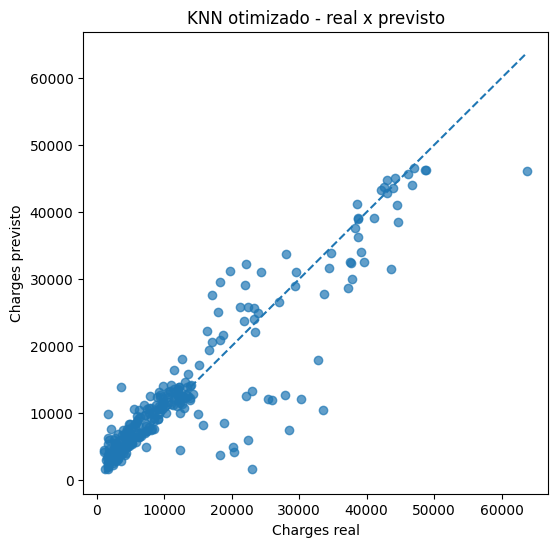

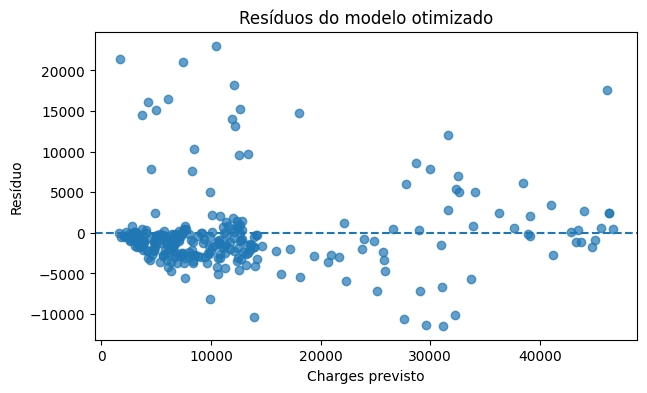

In [9]:
# gráfico de valores reais e previstos
plt.figure(figsize=(6, 6))
plt.scatter(y_test, pred_melhor, alpha=0.7)
# linha de referência: previsão perfeita
plt.plot([y_test.min(), y_test.max()], [y_test.min(), y_test.max()], linestyle="--")
plt.xlabel("Charges real")
plt.ylabel("Charges previsto")
plt.title("KNN otimizado - real x previsto")
plt.show()
# resíduos são a diferença entre real e previsto
residuos = y_test - pred_melhor
# vejo se existem erros muito grandes
plt.figure(figsize=(7, 4))
plt.scatter(pred_melhor, residuos, alpha=0.7)
plt.axhline(0, linestyle="--")
plt.xlabel("Charges previsto")
plt.ylabel("Resíduo")
plt.title("Resíduos do modelo otimizado")
plt.show()

## 9. Conclusão
A célula abaixo mostra automaticamente se as métricas melhoraram. Depois de executar, vale complementar com a interpretação dos números e dos gráficos, usando suas próprias palavras.

In [10]:
# verifico quais métricas realmente melhoraram
melhor_mae = resultados.loc[1, "MAE"] < resultados.loc[0, "MAE"]
melhor_mse = resultados.loc[1, "MSE"] < resultados.loc[0, "MSE"]
melhor_rmse = resultados.loc[1, "RMSE"] < resultados.loc[0, "RMSE"]
melhor_r2 = resultados.loc[1, "R2"] > resultados.loc[0, "R2"]
# mostro um resumo objetivo, sem afirmar melhoria quando não aconteceu
print("Melhorou MAE?", melhor_mae)
print("Melhorou MSE?", melhor_mse)
print("Melhorou RMSE?", melhor_rmse)
print("Melhorou R2?", melhor_r2)
# conclusão condicionada aos resultados reais
if melhor_mae and melhor_mse and melhor_rmse and melhor_r2:
    print("O KNN otimizado melhorou as quatro métricas no teste.")
else:
    print("O modelo não melhorou todas as métricas. É importante comentar quais pioraram.")
print("Limitações: o KNN depende da escala, da distância e dos vizinhos escolhidos.")
print("A nova variável pode ajudar ou não, dependendo dos dados.")

Melhorou MAE? True
Melhorou MSE? True
Melhorou RMSE? True
Melhorou R2? True
O KNN otimizado melhorou as quatro métricas no teste.
Limitações: o KNN depende da escala, da distância e dos vizinhos escolhidos.
A nova variável pode ajudar ou não, dependendo dos dados.


### Conclução Final

Neste trabalho, nosso objetivo foi melhorar o modelo KNN que fizemos na aula, utilizando o dataset Insurance.

Primeiro analisamos os dados, depois fizemos o tratamento das variáveis, utilizamos OneHotEncoder, StandardScaler e criamos uma nova variável chamada bmi_smoker, para tentar melhorar as previsões do modelo.

Também testamos diferentes parâmetros do KNN para encontrar a melhor combinação. O melhor resultado foi com 14 vizinhos, distância euclidiana e weights distance.

Comparando os resultados com o modelo da aula:

MAE: passou de 3631,59 para 2999,41.

MSE: passou de 35.984.260 para 24.689.840.

RMSE: passou de 5998,69 para 4968,89.

R²: passou de 0,7682 para 0,8410.

Com esses resultados, conseguimos melhorar todas as métricas. O R² chegou a aproximadamente 84%, mostrando que o modelo conseguiu explicar melhor a variação dos custos do seguro.

Nos gráficos também conseguimos ver que muitas previsões ficaram próximas dos valores reais, mas ainda temos alguns erros maiores, principalmente nos seguros com custos mais altos.

Uma limitação que observamos é que o KNN depende bastante da escala dos dados, da quantidade de vizinhos e da distância utilizada. Por isso, escolher os parâmetros corretos faz diferença no resultado.

Conclusão: conseguimos alcançar o objetivo do trabalho, melhorando o modelo que utilizamos na aula. Também entendemos na prática como o tratamento dos dados e a escolha dos parâmetros podem influenciar bastante o resultado de Machine Learning.